# Receptor-ligand proximity analysis

In [50]:
#import spacec as sp
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
import scipy as sci
import scipy.spatial.distance as distance
import imageio.v3 as iio
import warnings
from statannot import add_stat_annotation
warnings.filterwarnings("ignore")
plt.rcParams['axes.grid'] = False

In [51]:
from sklearn.neighbors import NearestNeighbors
import scipy as sp
import scipy.spatial
import scipy.spatial.distance as distance

def compute_ligRec(adata, 
                   ligand, # this is a column to be binary 0, 1, i.e. PD1_cluster_pos
                   receptor, # this is a column to be binary 0, 1, i.e. PDL1_cluster_pos
                   cellid = 'cellid',
                   x = 'x',
                   y = 'y',
                   pix_um_conv = 0.5085, #20x CODEX
                   k = 10, # k- nearest neighbors
                   d_thresh = 20,
                   filter = False
                  ):
    
    # the logic for this analysis will be the following
    # We will identify the cells that are positive for the receptor (e.g. PD-L1)
    adata_rep = adata[adata.obs[receptor]=='1']
    # then we get the dataframe of those cells, must include x, y, cellid, 
    df_rep = pd.DataFrame(adata_rep.obs)
    #create a new column that will stores the ligand if there are any cells | start with an empty cell

    #Set the target which is the ligand field
    adata_lig = adata[adata.obs[ligand]=='1']
    # using ligand as the area
    X = np.stack([adata_lig.obs['x'], adata_lig.obs['y']], axis = 1)
    #create a dictionary to convert the numeric index to cell id 
    df_lig = pd.DataFrame(adata_lig.obs)
    df_lig.reset_index(inplace=True)
    idx_to_cellid_dict = df_lig[cellid].to_dict()

    # store the rnn output as a dictionary
    knn_dict = {}

    # Now loop through each of the cells and run rnn and store the output in the interaction_PD1_cluster_pos
    for id in df_rep[cellid]:
        # subset the data
        tmp = df_rep.loc[df_rep[cellid] == id,:]
        cell_curr = np.stack([tmp[x], tmp[y]], axis = 1)
        d, inds = rnn(cell_curr, X, d_thresh/pix_um_conv)
        inds_id = np.array([idx_to_cellid_dict.get(value) for value in inds])
        knn_dict[id] = [d, inds_id]
    if filter:
        filtered_knn_dict = {k: v for k, v in knn_dict.items() if any(arr.size > 0 for arr in v)}
        adata.uns['filtered_knn_k' + str(k) + "_" + str(d_thresh) + "um_dict"] = filtered_knn_dict
        return filtered_knn_dict # will remove later
    else:
        adata.uns['knn_k' + str(k) + "_" + str(d_thresh) + "um_dict"] = knn_dict
        return knn_dict #will remove later
    
def visualize_lr_pairs(adata,
                       lr_key,
                       cell_curr,
                       receptor = 'PDL1_cluster_pos',
                       ligand = 'PD1_cluster_pos',
                       cellid = 'cellid',
                       x = 'x',
                       y = 'y',
                       figsize = (8,8),
                       s = 1,
                       title = "ligand_receptor_interactions"
                       ):
    adata_rep = adata[adata.obs[receptor]=='1']
    adata_lig = adata[adata.obs[ligand]=='1']
    X_lig = np.stack([adata_lig[adata_lig.obs[cellid].isin(adata_sub.uns[lr_key][cell_curr][1])].obs[x].values,
                    adata_lig[adata_lig.obs[cellid].isin(adata_sub.uns[lr_key][cell_curr][1])].obs[y].values], axis = 1)
    x_rep = np.stack([adata_rep[adata_rep.obs[cellid] == cell_curr].obs[x].values, 
                      adata_rep[adata_rep.obs[cellid] == cell_curr].obs[y].values], axis=1)
    
    plt.figure(figsize=figsize)
    plt.title(title)
    plt.scatter(adata_rep.obs[x], adata_rep.obs[y], c='b', s = s) #background of all receptor pos cells
    plt.scatter(X_lig[:,0], X_lig[:,1], c='r', s= s) #ligand pos
    plt.scatter(x_rep[0][0], x_rep[0][1], c='black', s = s + 2) #receptor pos
    plt.show()

In [151]:
# load demo TMA
adata = sc.read('/Users/maxhaist/Nolan Lab Dropbox/Maximilian Haist/MCC_project/Data/CODEX/submission/MCC_single_cell_neighborhoods_markers.h5ad')
adata_sub = adata[adata.obs['unique_core_num'] == 'TMA_41_K4'] ## as demo to check proximity of RL pairs visually
adata_sub

View of AnnData object with n_obs × n_vars = 27185 × 58
    obs: 'x', 'y', 'TMA_num', 'cellid', 'UID', 'unique_region_num', 'unique_core_num', 'TMA_core_num', 'cell_types_lowres', 'cell_types_mediumres', 'cell_types_highres', 'tissue_compartments', 'PDL1_cluster_pos', 'PD1_cluster_pos', 'CXCL9_pos', 'CXCL10_pos', 'CXCR3_pos', 'CXCL13_pos', 'CXCR5_pos', 'Exhausted_cluster', 'TCF17_pos', 'Ki67_pos', 'T_cell_memory', 'IL10_pos', 'HLADR_pos', 'Hypoxic_tumor', 'T_cell_subtypes', 'CN_k20_n25_annot'
    obsm: 'X_umap'

In [152]:
adata.obs["unique_core_num"].unique()

['TMA_1_K7', 'TMA_1_L7', 'TMA_1_M7', 'TMA_1_B7', 'TMA_1_C7', ..., 'TMA_44_G1', 'TMA_44_J5', 'TMA_1_L2', 'TMA_3_L2', 'TMA_41_H1']
Length: 356
Categories (356, object): ['TMA_1_A1', 'TMA_1_A2', 'TMA_1_A3', 'TMA_1_A4', ..., 'TMA_44_M1', 'TMA_44_M2', 'TMA_44_N1', 'TMA_44_N3']

In [153]:
def rnn(x, X, r, **kwargs):
    """
    find r-nearest neighbors of x in X
    """
    d = distance.cdist(x.reshape(1,-1), X, **kwargs).flatten()
    return d[np.where(d<r)[0]], np.where(d<r)[0]

In [154]:
# getting PD1 and PDL1 information across region
lr_dict = {}
for reg_num in adata.obs['unique_core_num'].unique():
    print(reg_num)
    adata_tmp = adata[adata.obs['unique_core_num'] == reg_num]
    lr_dict[reg_num] = compute_ligRec(adata = adata_tmp, 
                               ligand = 'PD1_cluster_pos',
                               receptor= 'PDL1_cluster_pos', ##receptor serves as the anchoring cell
                               x = 'x',
                               y = 'y',
                               cellid='cellid',
                               pix_um_conv = 0.5085, #conversion of pixel in µm: 20x CODEX
                               d_thresh = 20, #distance threshold in µm
                               filter=True # if true, the cells without 
                               )
    

TMA_1_K7
TMA_1_L7
TMA_1_M7
TMA_1_B7
TMA_1_C7
TMA_1_D7
TMA_1_E7
TMA_1_F7
TMA_1_I7
TMA_1_J6
TMA_1_L6
TMA_1_M6
TMA_1_B6
TMA_1_C6
TMA_1_D6
TMA_1_E6
TMA_1_F6
TMA_1_G6
TMA_1_I6
TMA_1_A5
TMA_1_J5
TMA_1_K5
TMA_1_L5
TMA_1_M5
TMA_1_B5
TMA_1_C5
TMA_1_D5
TMA_1_E5
TMA_1_G5
TMA_1_H5
TMA_1_I5
TMA_1_A4
TMA_1_J4
TMA_1_K4
TMA_1_L4
TMA_1_M4
TMA_1_B4
TMA_1_C4
TMA_1_D4
TMA_1_E4
TMA_1_F4
TMA_1_H4
TMA_1_I4
TMA_1_A3
TMA_1_J3
TMA_1_K3
TMA_1_L3
TMA_1_M3
TMA_1_N3
TMA_1_B3
TMA_1_C3
TMA_1_D3
TMA_1_E3
TMA_1_F3
TMA_1_G3
TMA_1_H3
TMA_1_I3
TMA_1_A2
TMA_1_J2
TMA_1_K2
TMA_1_M2
TMA_1_N2
TMA_1_B2
TMA_1_C2
TMA_1_D2
TMA_1_E2
TMA_1_F2
TMA_1_G2
TMA_1_H2
TMA_1_A1
TMA_1_J1
TMA_1_K1
TMA_1_L1
TMA_1_M1
TMA_1_N1
TMA_1_B1
TMA_1_C1
TMA_1_E1
TMA_1_F1
TMA_1_G1
TMA_1_H1
TMA_1_I1
TMA_2_M7
TMA_2_F6
TMA_2_A3
TMA_2_N3
TMA_2_C3
TMA_2_E3
TMA_2_I2
TMA_2_M1
TMA_22_K7
TMA_22_L7
TMA_22_M7
TMA_22_B7
TMA_22_F7
TMA_22_J6
TMA_22_K6
TMA_22_L6
TMA_22_M6
TMA_22_F6
TMA_22_A5
TMA_22_J5
TMA_22_M5
TMA_22_C5
TMA_22_H5
TMA_22_K4
TMA_22_F4
TMA_22_J3
TMA_22_K3


In [155]:
interaction_pair_df = pd.DataFrame(lr_dict.keys(), columns=['unique_core_num'])
interaction_pair_df['pd1_pdl1_pairs'] = 0
for reg_num in lr_dict.keys():
    interaction_pair_df.loc[interaction_pair_df['unique_core_num'] == reg_num, "pd1_pdl1_pairs"] = len(lr_dict[reg_num])

In [156]:
interaction_pair_df['TMA'] = interaction_pair_df['unique_core_num'].str.extract(r'(TMA_\d+)')
interaction_pair_df.head()

,unique_core_num,pd1_pdl1_pairs,TMA
0,TMA_1_K7,18,TMA_1
1,TMA_1_L7,101,TMA_1
2,TMA_1_M7,92,TMA_1
3,TMA_1_B7,636,TMA_1
4,TMA_1_C7,95,TMA_1


In [157]:
interaction_pair_df.index = interaction_pair_df.unique_core_num

In [158]:
# read in clinical data
clin_df = pd.read_csv('/Users/maxhaist/Nolan Lab Dropbox/Maximilian Haist/MCC_project/Data/CODEX/submission/Clin_meta_dict_MCC_290424_unique_region_num.csv', index_col=0)
clin_df.index = clin_df.unique_core_num
clin_df.head()

,Pat_ID,Gender,Age_diagnosis,Localization_biopsy,Localization_primary,tumor_thickness_mm,T,N,M,Stage_ED,...,MCPyV_positive_FU,p53_CODEX,pRB_CODEX,MHC-I_CODEX,MHC-I_IHC,HandE_phenotype,MHCI_IHC_summary,TMA_num,unique_region_num,unique_core_num
unique_core_num,,,,,,,,,,,,,,,,,,,,,
TMA_1_J4,1,m,70,5,CUP,NaN,0.0,2,0,3b,...,NaN,low,low,high,high,excluded,intermediate,TMA_1,TMA_1_reg044,TMA_1_J4
TMA_2_J4,1,m,70,5,CUP,NaN,0.0,2,0,3b,...,NaN,low,low,high,high,excluded,intermediate,TMA_2,TMA_2_reg044,TMA_2_J4
TMA_3_J4,1,m,70,5,CUP,NaN,0.0,2,0,3b,...,NaN,low,low,high,high,excluded,intermediate,TMA_3,TMA_3_reg044,TMA_3_J4
TMA_41_J4,1,m,70,5,CUP,NaN,0.0,2,0,3b,...,NaN,low,low,high,high,excluded,intermediate,TMA_41,TMA_41_reg044,TMA_41_J4
TMA_22_J4,1,m,70,5,CUP,NaN,0.0,2,0,3b,...,NaN,low,low,high,high,excluded,intermediate,TMA_22,TMA_22_reg044,TMA_22_J4


In [159]:
shared_tma_reg_num = np.intersect1d(clin_df.index, interaction_pair_df.index)
interaction_pair_df_shared = interaction_pair_df.loc[shared_tma_reg_num,:]
print(interaction_pair_df_shared.shape)
clin_df_shared = clin_df.loc[shared_tma_reg_num,:]
print(clin_df_shared.shape)

(356, 3)
(356, 109)


In [173]:
interaction_pair_df_clin = pd.concat([interaction_pair_df_shared, clin_df_shared], axis=1)
interaction_pair_df_clin.head()

,unique_core_num,pd1_pdl1_pairs,TMA,Pat_ID,Gender,Age_diagnosis,Localization_biopsy,Localization_primary,tumor_thickness_mm,T,...,MCPyV_positive_FU,p53_CODEX,pRB_CODEX,MHC-I_CODEX,MHC-I_IHC,HandE_phenotype,MHCI_IHC_summary,TMA_num,unique_region_num,unique_core_num
unique_core_num,,,,,,,,,,,,,,,,,,,,,
TMA_1_A1,TMA_1_A1,488,TMA_1,18,m,80,1,Head,11.0,1.0,...,NaN,intermediate,intermediate,intermediate,intermediate,brisk,intermediate,TMA_1,TMA_1_reg085,TMA_1_A1
TMA_1_A2,TMA_1_A2,513,TMA_1,21,f,83,2,upper limb,19.0,2.0,...,NaN,intermediate,intermediate,intermediate,intermediate,excluded,intermediate,TMA_1,TMA_1_reg071,TMA_1_A2
TMA_1_A3,TMA_1_A3,127,TMA_1,24,f,69,4,trunk,10.0,2.0,...,NaN,intermediate,low,low,intermediate,brisk,positive,TMA_1,TMA_1_reg057,TMA_1_A3
TMA_1_A4,TMA_1_A4,813,TMA_1,26,m,83,1,Head,18.0,1.0,...,NaN,low,low,high,high,excluded,intermediate,TMA_1,TMA_1_reg043,TMA_1_A4
TMA_1_A5,TMA_1_A5,551,TMA_1,51,m,61,4,trunk,13.0,2.0,...,NaN,low,low,low,intermediate,excluded,low,TMA_1,TMA_1_reg029,TMA_1_A5


In [174]:
## Select only untreated samples for comparing VP vs VN conditions
interaction_pair_df_clin = interaction_pair_df_clin[interaction_pair_df_clin["Baseline_FU_biopsy"].isin(["pre", "FU"])]
interaction_pair_df_clin

,unique_core_num,pd1_pdl1_pairs,TMA,Pat_ID,Gender,Age_diagnosis,Localization_biopsy,Localization_primary,tumor_thickness_mm,T,...,MCPyV_positive_FU,p53_CODEX,pRB_CODEX,MHC-I_CODEX,MHC-I_IHC,HandE_phenotype,MHCI_IHC_summary,TMA_num,unique_region_num,unique_core_num
unique_core_num,,,,,,,,,,,,,,,,,,,,,
TMA_1_A1,TMA_1_A1,488,TMA_1,18,m,80,1,Head,11.0,1.0,...,NaN,intermediate,intermediate,intermediate,intermediate,brisk,intermediate,TMA_1,TMA_1_reg085,TMA_1_A1
TMA_1_A2,TMA_1_A2,513,TMA_1,21,f,83,2,upper limb,19.0,2.0,...,NaN,intermediate,intermediate,intermediate,intermediate,excluded,intermediate,TMA_1,TMA_1_reg071,TMA_1_A2
TMA_1_A3,TMA_1_A3,127,TMA_1,24,f,69,4,trunk,10.0,2.0,...,NaN,intermediate,low,low,intermediate,brisk,positive,TMA_1,TMA_1_reg057,TMA_1_A3
TMA_1_A4,TMA_1_A4,813,TMA_1,26,m,83,1,Head,18.0,1.0,...,NaN,low,low,high,high,excluded,intermediate,TMA_1,TMA_1_reg043,TMA_1_A4
TMA_1_A5,TMA_1_A5,551,TMA_1,51,m,61,4,trunk,13.0,2.0,...,NaN,low,low,low,intermediate,excluded,low,TMA_1,TMA_1_reg029,TMA_1_A5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TMA_6_B_1,TMA_6_B_1,1,TMA_6,11,m,84,1,Head,6.3,1.0,...,NaN,high,low,low,low,anergic,intermediate,TMA_6,TMA_6_reg008,TMA_6_B_1
TMA_6_B_3,TMA_6_B_3,45,TMA_6,11,m,84,1,Head,6.3,1.0,...,NaN,high,low,low,low,anergic,intermediate,TMA_6,TMA_6_reg007,TMA_6_B_3
TMA_6_B_4,TMA_6_B_4,0,TMA_6,11,m,84,1,Head,6.3,1.0,...,NaN,high,low,low,low,anergic,intermediate,TMA_6,TMA_6_reg009,TMA_6_B_4


In [175]:
# Define custom color palette
custom_palette_viral_status = {
    "negative": "royalblue",
    "positive": "red"
}

custom_palette_ICB_response = {
    "NR": "orange",
    "R": "green"
}

In [185]:
save_path = "/Users/maxhaist/Nolan Lab Dropbox/Maximilian Haist/MCC_project/Output_R_analysis/RL_analysis/"

p-value annotation legend:
ns: 5.00e-02 < p <= 1.00e+00
*: 1.00e-02 < p <= 5.00e-02
**: 1.00e-03 < p <= 1.00e-02
***: 1.00e-04 < p <= 1.00e-03
****: p <= 1.00e-04

negative v.s. positive: t-test independent samples with Bonferroni correction, P_val=3.566e-04 stat=-3.611e+00


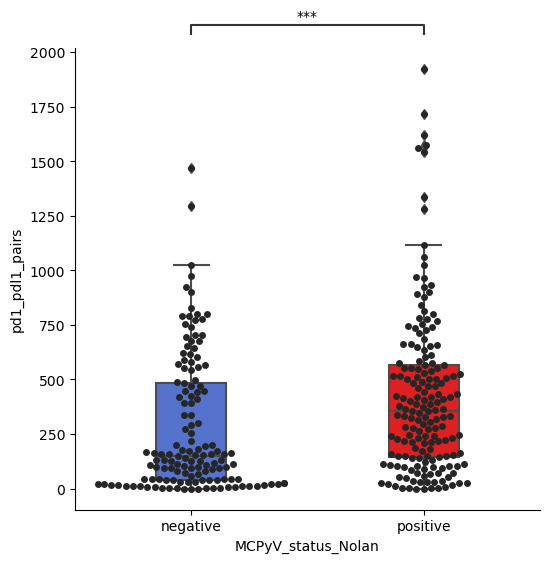

In [177]:
from statannot import add_stat_annotation

interaction_pair_df_clin["MCPyV_status_Nolan"] = pd.Categorical(
    interaction_pair_df_clin["MCPyV_status_Nolan"], 
    categories=["negative", "positive"], 
    ordered=True
)

plt.figure(figsize=(6, 6))
ax = sns.boxplot(x="MCPyV_status_Nolan", y="pd1_pdl1_pairs", data=interaction_pair_df_clin, showfliers=True, palette=custom_palette_viral_status, width=0.3)

# Overlay the swarmplot
sns.swarmplot(x="MCPyV_status_Nolan", y="pd1_pdl1_pairs", data=interaction_pair_df_clin, color=".15", ax=ax, dodge=True)

# Add t-test annotations
add_stat_annotation(ax, 
                    data=interaction_pair_df_clin, 
                    x="MCPyV_status_Nolan", 
                    y="pd1_pdl1_pairs",
                    box_pairs=[("positive", "negative")],
                    test='t-test_ind', 
                    text_format='star', 
                    loc='outside', 
                    verbose=2)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

plt.savefig(save_path + "Boxplot_viral_status_RL_pairs_021124.pdf", dpi=300)
# Display the plot
plt.show()

In [178]:
interaction_pair_df_clin = interaction_pair_df_clin.dropna(subset=['CPI_ORR'])

In [182]:
interaction_pair_df_clin.CPI_ORR

unique_core_num
TMA_1_A4      R
TMA_1_B2     NR
TMA_1_C7     NR
TMA_1_D2      R
TMA_1_D3     NR
             ..
TMA_6_B_1    NR
TMA_6_B_3    NR
TMA_6_B_4    NR
TMA_6_B_5    NR
TMA_6_C_1    NR
Name: CPI_ORR, Length: 147, dtype: object

In [180]:
interaction_pair_df_clin['CPI_ORR'] = interaction_pair_df_clin['CPI_ORR'].replace({0: 'NR', 1: 'R'})
interaction_pair_df_clin

,unique_core_num,pd1_pdl1_pairs,TMA,Pat_ID,Gender,Age_diagnosis,Localization_biopsy,Localization_primary,tumor_thickness_mm,T,...,MCPyV_positive_FU,p53_CODEX,pRB_CODEX,MHC-I_CODEX,MHC-I_IHC,HandE_phenotype,MHCI_IHC_summary,TMA_num,unique_region_num,unique_core_num
unique_core_num,,,,,,,,,,,,,,,,,,,,,
TMA_1_A4,TMA_1_A4,813,TMA_1,26,m,83,1,Head,18.0,1.0,...,NaN,low,low,high,high,excluded,intermediate,TMA_1,TMA_1_reg043,TMA_1_A4
TMA_1_B2,TMA_1_B2,226,TMA_1,25,m,73,2,upper limb,6.4,2.0,...,NaN,low,high,high,intermediate,excluded,low,TMA_1,TMA_1_reg077,TMA_1_B2
TMA_1_C7,TMA_1_C7,95,TMA_1,76,f,58,2,upper limb,NaN,2.0,...,NaN,low,low,low,low,anergic,low,TMA_1,TMA_1_reg008,TMA_1_C7
TMA_1_D2,TMA_1_D2,216,TMA_1,4,m,80,2,upper limb,23.0,2.0,...,NaN,low,low,low,intermediate,excluded,low,TMA_1,TMA_1_reg079,TMA_1_D2
TMA_1_D3,TMA_1_D3,411,TMA_1,5,m,66,5,CUP,NaN,0.0,...,NaN,high,high,intermediate,low,anergic,intermediate,TMA_1,TMA_1_reg065,TMA_1_D3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TMA_6_B_1,TMA_6_B_1,1,TMA_6,11,m,84,1,Head,6.3,1.0,...,NaN,high,low,low,low,anergic,intermediate,TMA_6,TMA_6_reg008,TMA_6_B_1
TMA_6_B_3,TMA_6_B_3,45,TMA_6,11,m,84,1,Head,6.3,1.0,...,NaN,high,low,low,low,anergic,intermediate,TMA_6,TMA_6_reg007,TMA_6_B_3
TMA_6_B_4,TMA_6_B_4,0,TMA_6,11,m,84,1,Head,6.3,1.0,...,NaN,high,low,low,low,anergic,intermediate,TMA_6,TMA_6_reg009,TMA_6_B_4


p-value annotation legend:
ns: 5.00e-02 < p <= 1.00e+00
*: 1.00e-02 < p <= 5.00e-02
**: 1.00e-03 < p <= 1.00e-02
***: 1.00e-04 < p <= 1.00e-03
****: p <= 1.00e-04

R v.s. NR: t-test independent samples with Bonferroni correction, P_val=1.416e-06 stat=5.032e+00


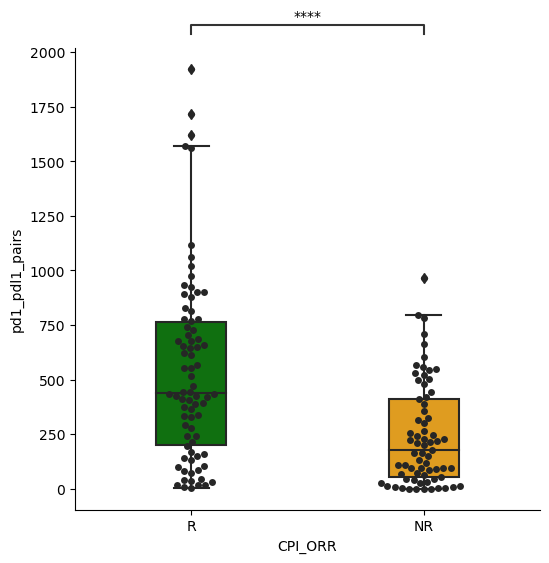

In [184]:
# Create the boxplot with adjusted width
plt.figure(figsize=(6, 6))
ax = sns.boxplot(x="CPI_ORR", y="pd1_pdl1_pairs", data=interaction_pair_df_clin, showfliers=True, palette=custom_palette_ICB_response, width=0.3)

# Overlay the swarmplot
sns.swarmplot(x="CPI_ORR", y="pd1_pdl1_pairs", data=interaction_pair_df_clin, color=".15", ax=ax, dodge=True)

# Add t-test annotations
add_stat_annotation(ax, 
                    data=interaction_pair_df_clin, 
                    x="CPI_ORR", 
                    y="pd1_pdl1_pairs",
                    box_pairs=[("R", "NR")],
                    test='t-test_ind', 
                    text_format='star', 
                    loc='outside', 
                    verbose=2)

# Remove the outline of the plot by modifying the spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Remove the grid
ax.grid(False)

# Save the plot as a .pdf file with 300 dpi resolution
#plt.savefig(save_path + "Boxplot_ICB_response_status_RL_pairs.pdf", dpi=300)

# Display the plot
plt.show()

## Compute for LR interaction (distance) in specific region

In [27]:
# compute for ligand receptor interaction for PD1 and PD1_L1 for a given TMA region
# the resultant dictionary is stored in uns e.g. adata_sub.uns['filtered_knn_k10_20um_dict'], 
# dict keys are the cellid, the corresponding field equals to the inds of the ligand+ cell id 
compute_ligRec(adata = adata_sub, 
                               ligand = 'PD1_cluster_pos',
                               receptor= 'PDL1_cluster_pos',
                               x = 'x',
                               y = 'y',
                               cellid='cellid',
                               pix_um_conv = 0.5085, #20x CODEX
                               d_thresh = 20, # in um
                               filter=True # if true, the cells without 
                               )
adata_sub

AnnData object with n_obs × n_vars = 27185 × 58
    obs: 'x', 'y', 'region_num', 'TMA_num', 'cellid', 'UID', 'unique_region_num', 'unique_core_num', 'TMA_core_num', 'cell_types_lowres', 'cell_types_mediumres', 'cell_types_highres', 'tissue_compartments', 'subcluster_residency', 'subcluster_FDC_TFH', 'PDL1_cluster_pos', 'PD1_cluster_pos', 'CXCL9_pos', 'CXCL10_pos', 'CXCR3_pos', 'CXCL13_pos', 'CXCR5_pos', 'PDL1_pos_gate', 'PD1_pos_gate', 'Exhausted_cluster', 'Exhausted_dichotomized'
    uns: 'filtered_knn_k10_20um_dict'
    obsm: 'X_umap'

In [31]:
compute_ligRec(adata = adata_sub, 
                               ligand = 'PD1_cluster_pos',
                               receptor= 'PDL1_cluster_pos',
                               x = 'x',
                               y = 'y',
                               cellid='cellid',
                               pix_um_conv = 0.5085, #20x CODEX
                               d_thresh = 20, # in um
                               filter=False # if true, the cells without 
                               )
adata_sub

AnnData object with n_obs × n_vars = 27185 × 58
    obs: 'x', 'y', 'region_num', 'TMA_num', 'cellid', 'UID', 'unique_region_num', 'unique_core_num', 'TMA_core_num', 'cell_types_lowres', 'cell_types_mediumres', 'cell_types_highres', 'tissue_compartments', 'subcluster_residency', 'subcluster_FDC_TFH', 'PDL1_cluster_pos', 'PD1_cluster_pos', 'CXCL9_pos', 'CXCL10_pos', 'CXCR3_pos', 'CXCL13_pos', 'CXCR5_pos', 'PDL1_pos_gate', 'PD1_pos_gate', 'Exhausted_cluster', 'Exhausted_dichotomized'
    uns: 'filtered_knn_k10_20um_dict', 'knn_k10_20um_dict'
    obsm: 'X_umap'

In [32]:
len(adata_sub.uns['knn_k10_20um_dict'])

2372

In [29]:
len(adata_sub.uns['filtered_knn_k10_20um_dict'])

1454

In [30]:
adata_sub.uns["filtered_knn_k10_20um_dict"]

{'295127': [array([16.55294536]), array(['305640'], dtype='<U6')],
 '295128': [array([ 9.43398113, 11.04536102, 22.84731932, 17.88854382, 29.06888371,
         34.05877273]),
  array(['296540', '302698', '312577', '313248', '316486', '317055'],
        dtype='<U6')],
 '295130': [array([36.05551275, 37.73592453, 32.55764119, 23.53720459, 16.55294536]),
  array(['298313', '302278', '307204', '308706', '312043'], dtype='<U6')],
 '295132': [array([15.65247584]), array(['305818'], dtype='<U6')],
 '295141': [array([33.60059523]), array(['296696'], dtype='<U6')],
 '295167': [array([37.48332963]), array(['311855'], dtype='<U6')],
 '295181': [array([29.73213749, 32.69556545, 17.11724277]),
  array(['295213', '316342', '317581'], dtype='<U6')],
 '295185': [array([36.87817783, 34.05877273]),
  array(['311146', '320567'], dtype='<U6')],
 '295189': [array([12.08304597, 29.06888371]),
  array(['295269', '318418'], dtype='<U6')],
 '295212': [array([33.52610923, 34.98571137]),
  array(['299619', '3032

## Visualization (example)

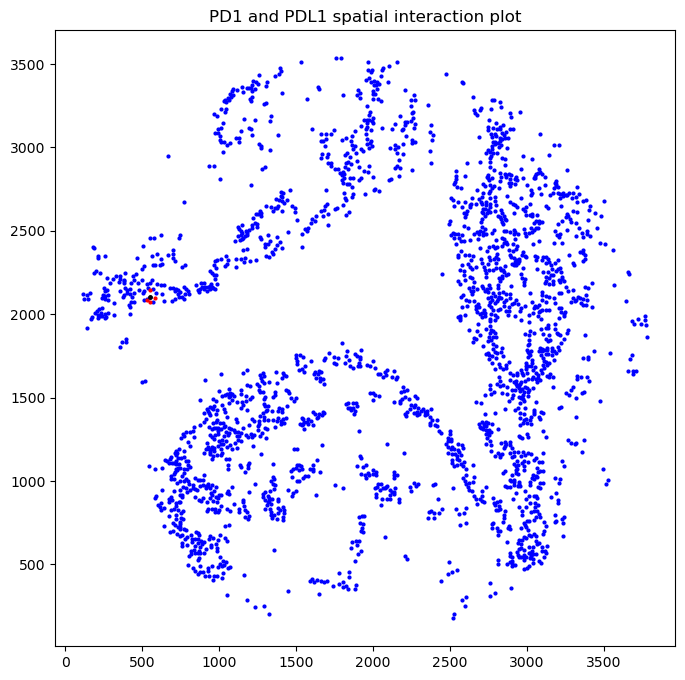

In [33]:
# Based on the x y distance
cell_curr = '312545' # we are looking at this particular PDL1+ cell as an example
visualize_lr_pairs(adata = adata_sub,
                       lr_key = 'filtered_knn_k10_20um_dict',
                       cell_curr = cell_curr,
                       receptor = 'PDL1_cluster_pos',
                       ligand = 'PD1_cluster_pos',
                       cellid = 'cellid', 
                       x = 'x',
                       y = 'y',
                       s = 4,
                       title= "PD1 and PDL1 spatial interaction plot")

## Check receptor-ligand positivity

In [34]:
# start here
#import spacec as sp
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
import scipy as sci
import scipy.spatial.distance as distance
import imageio.v3 as iio
import warnings
warnings.filterwarnings("ignore")
plt.rcParams['axes.grid'] = False

In [35]:
data_dir = "/Users/maxhaist/Nolan Lab Dropbox/Maximilian Haist/Max/Merkel_cell/CODEX_data/" # you need to change this for your path
codex_path = data_dir + "ReceptorLigand_interaction_analysis/masks/TMA_41/reg018_X01_Y01_Z01.tif"
print(codex_path)

/Users/maxhaist/Nolan Lab Dropbox/Maximilian Haist/Max/Merkel_cell/CODEX_data/ReceptorLigand_interaction_analysis/masks/TMA_41/reg018_X01_Y01_Z01.tif


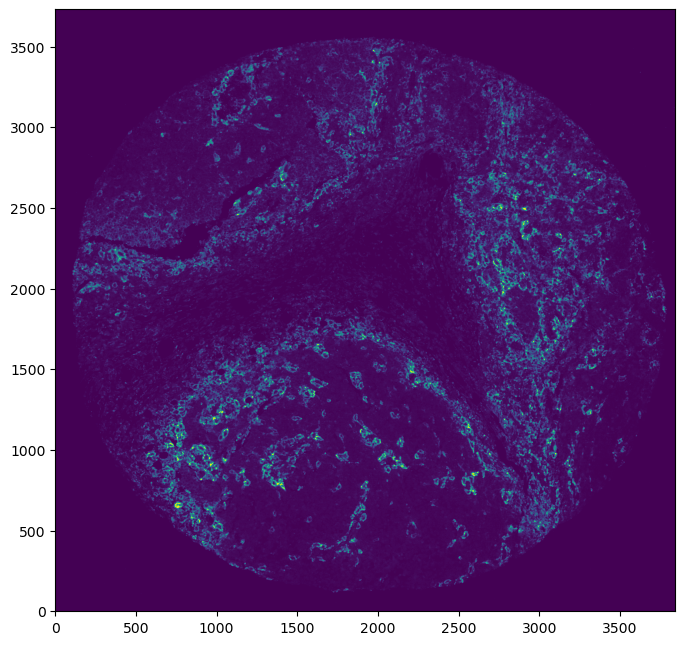

In [36]:
# read codex
codex = iio.imread(codex_path, index=None)
pdl1_ch_idx = 13

# plot
codex_pdl1 = codex[pdl1_ch_idx, :, :]
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.imshow(codex_pdl1)
ax.invert_yaxis()

In [37]:
cell_curr = '312545'
cellid = 'cellid'
lig_id = adata_sub.uns['filtered_knn_k10_20um_dict'][cell_curr][1]
lig_id = np.append(lig_id, cell_curr)
adata_sub_lr = adata_sub[adata_sub.obs[cellid].isin(lig_id)] 
adata_sub_lr

View of AnnData object with n_obs × n_vars = 5 × 58
    obs: 'x', 'y', 'region_num', 'TMA_num', 'cellid', 'UID', 'unique_region_num', 'unique_core_num', 'TMA_core_num', 'cell_types_lowres', 'cell_types_mediumres', 'cell_types_highres', 'tissue_compartments', 'subcluster_residency', 'subcluster_FDC_TFH', 'PDL1_cluster_pos', 'PD1_cluster_pos', 'CXCL9_pos', 'CXCL10_pos', 'CXCR3_pos', 'CXCL13_pos', 'CXCR5_pos', 'PDL1_pos_gate', 'PD1_pos_gate', 'Exhausted_cluster', 'Exhausted_dichotomized'
    uns: 'filtered_knn_k10_20um_dict', 'knn_k10_20um_dict'
    obsm: 'X_umap'

In [38]:
# involve masks and 
img_path = adata_sub_lr.obs['unique_region_num'].unique()[0].split("_")[0] + "_" + adata_sub_lr.obs['unique_region_num'].unique()[0].split("_")[1] + "/"+ adata_sub_lr.obs['unique_region_num'].unique()[0].split("_")[2]
print(img_path)
mask_path = img_path  + '_X01_Y01_Z01_visual_us3.0_grow0.0x3.0x1.0b2.5_masks.png'
print(mask_path)
codex_path = img_path  + '_X01_Y01_Z01.tif'
print(codex_path)

TMA_41/reg018
TMA_41/reg018_X01_Y01_Z01_visual_us3.0_grow0.0x3.0x1.0b2.5_masks.png
TMA_41/reg018_X01_Y01_Z01.tif


In [39]:
masks = iio.imread(str(data_dir + 'ReceptorLigand_interaction_analysis/masks/' + mask_path), index=None)
print(masks.shape)

## read in CODEX data the
# channel for PD-L1 is 13, the channel for PD-1 is 32
codex = iio.imread(str(data_dir + 'ReceptorLigand_interaction_analysis/masks/' + codex_path), index=None)
pdl1_ch_idx = 13
pd1_ch_idx = 32
print(codex.shape)

(3731, 3843, 3)
(59, 3731, 3843)


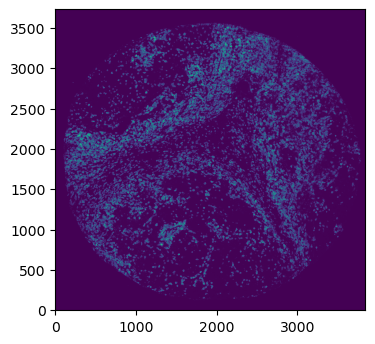

In [40]:
codex_pd1 = codex[pd1_ch_idx, :, :]
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.imshow(codex_pd1)
ax.invert_yaxis()

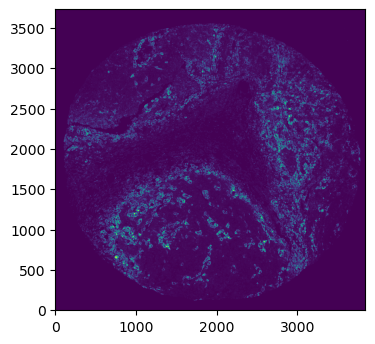

In [41]:
codex_pdl1 = codex[pdl1_ch_idx, :, :]
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.imshow(codex_pdl1)
ax.invert_yaxis()


In [42]:
codex_dapi = codex[0, :, :]

In [43]:
adata_sub_lr.obs['cellid']

5854277    296230
5870590    312545
5874507    316465
5877028    318987
5877981    319940
Name: cellid, dtype: category
Categories (5, object): ['296230', '312545', '316465', '318987', '319940']

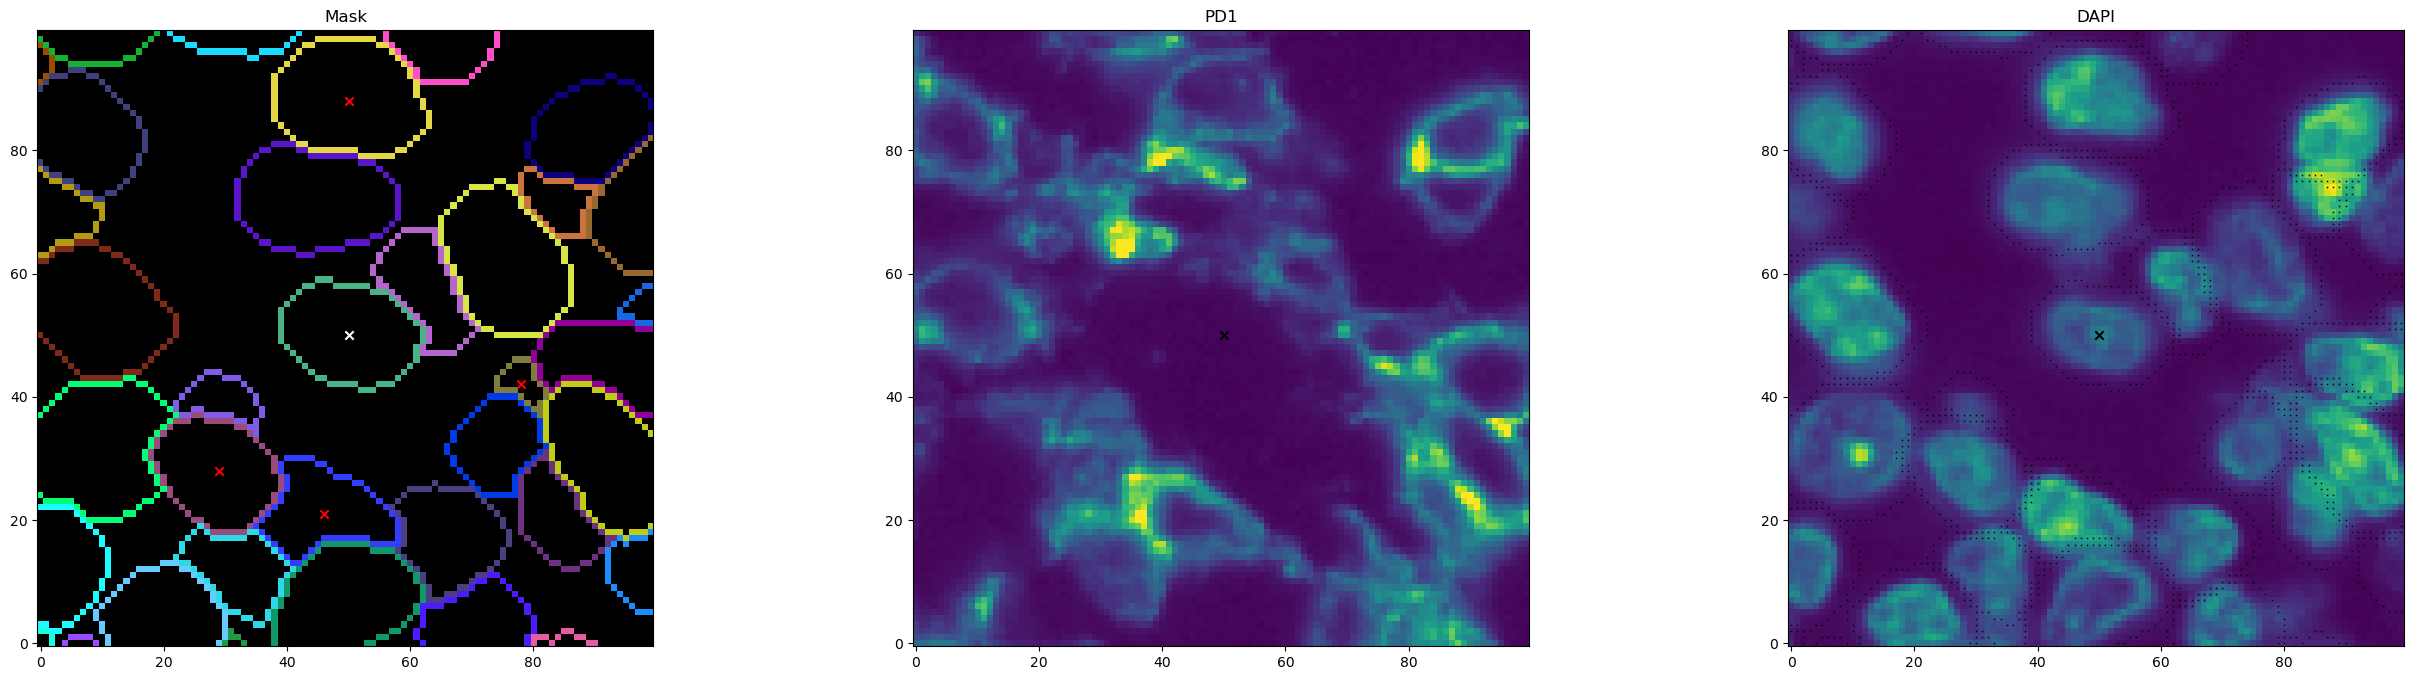

In [44]:
padding = 50
x, y = adata_sub_lr[adata_sub_lr.obs[cellid]==cell_curr].obs["x"].values[0], adata_sub_lr[adata_sub_lr.obs[cellid]==cell_curr].obs["y"].values[0]
x_lig, y_lig = adata_sub_lr[adata_sub_lr.obs[cellid]!=cell_curr].obs["x"].values, adata_sub_lr[adata_sub_lr.obs[cellid]!=cell_curr].obs["y"].values
x_min, x_max = int(max(0, x - padding)), int(min(x + padding, masks.shape[1]))
y_min, y_max = int(max(0, y - padding)), int(min(y + padding, masks.shape[0]))

fig, axes = plt.subplots(1, 3, figsize=(8 * 4, 8))

ax = axes[0]
ax.imshow(masks[y_min:y_max, x_min:x_max])
ax.scatter([x - x_min], [y - y_min], c="white", marker="x")
ax.scatter([x_lig - x_min], [y_lig - y_min], c="red", marker="x")
ax.invert_yaxis()
ax.set_title("Mask")

ax = axes[1]
ax.imshow(codex_pd1[y_min:y_max, x_min:x_max], cmap="viridis")
ax.scatter([x - x_min], [y - y_min],c ="black", marker="x")
ax.invert_yaxis()
ax.set_title("PD1")

ax = axes[2]
ax.imshow(codex_dapi[y_min:y_max, x_min:x_max], cmap="viridis")
ax.scatter([x - x_min], [y - y_min], c="black", marker="x")
ax.invert_yaxis()
ax.set_title("DAPI")

#ax = axes[2]
#ax.imshow(codex_pd1[y_min:y_max, x_min:x_max])
#ax.scatter([x - x_min], [y - y_min], c="black", marker="x")

xx, yy = np.where(masks[y_min:y_max, x_min:x_max].sum(axis=2) > 0)
ax.scatter(yy, xx, c="black", marker="x", s=0.1)

ax.grid(False)

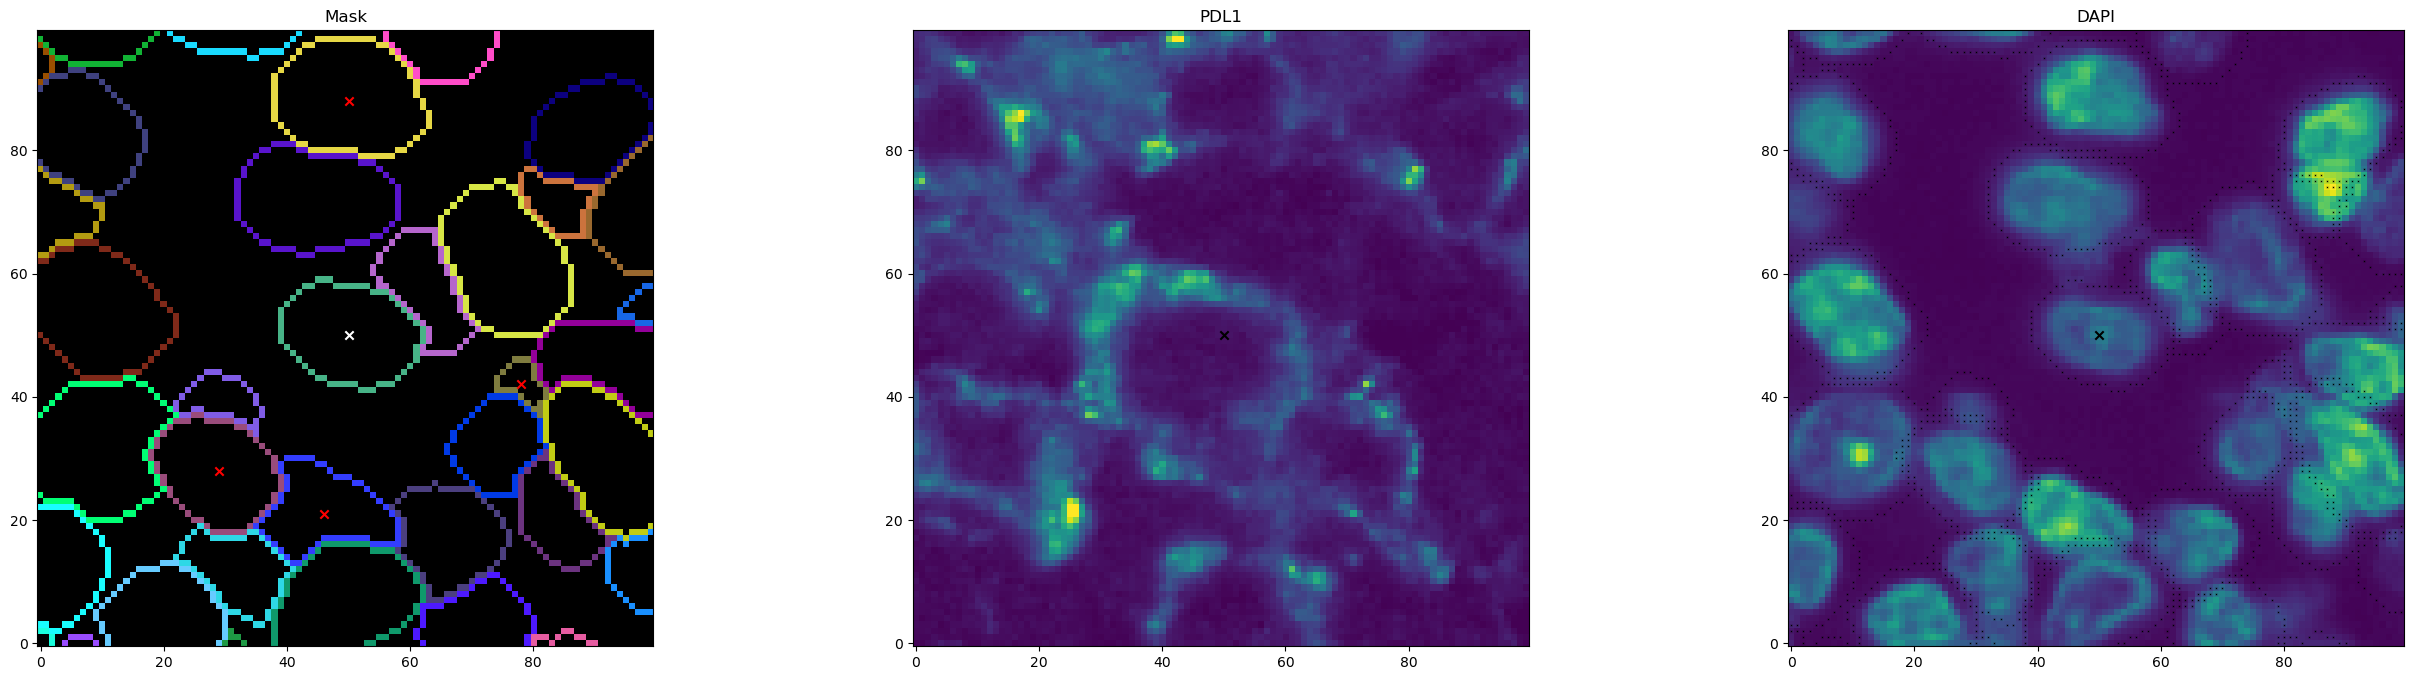

In [45]:
padding = 50
x, y = adata_sub_lr[adata_sub_lr.obs[cellid]==cell_curr].obs["x"].values[0], adata_sub_lr[adata_sub_lr.obs[cellid]==cell_curr].obs["y"].values[0]
x_lig, y_lig = adata_sub_lr[adata_sub_lr.obs[cellid]!=cell_curr].obs["x"].values, adata_sub_lr[adata_sub_lr.obs[cellid]!=cell_curr].obs["y"].values
x_min, x_max = int(max(0, x - padding)), int(min(x + padding, masks.shape[1]))
y_min, y_max = int(max(0, y - padding)), int(min(y + padding, masks.shape[0]))

fig, axes = plt.subplots(1, 3, figsize=(8 * 4, 8))

ax = axes[0]
ax.imshow(masks[y_min:y_max, x_min:x_max])
ax.scatter([x - x_min], [y - y_min], c="white", marker="x")
ax.scatter([x_lig - x_min], [y_lig - y_min], c="red", marker="x")
ax.invert_yaxis()
ax.set_title("Mask")

ax = axes[1]
ax.imshow(codex_pdl1[y_min:y_max, x_min:x_max], cmap="viridis")
ax.scatter([x - x_min], [y - y_min],c ="black", marker="x")
ax.invert_yaxis()
ax.set_title("PDL1")

ax = axes[2]
ax.imshow(codex_dapi[y_min:y_max, x_min:x_max], cmap="viridis")
ax.scatter([x - x_min], [y - y_min], c="black", marker="x")
ax.invert_yaxis()
ax.set_title("DAPI")

#ax = axes[2]
#ax.imshow(codex_pd1[y_min:y_max, x_min:x_max])
#ax.scatter([x - x_min], [y - y_min], c="black", marker="x")

xx, yy = np.where(masks[y_min:y_max, x_min:x_max].sum(axis=2) > 0)
ax.scatter(yy, xx, c="black", marker="x", s=0.1)

ax.grid(False)